# SUN RGB-D class analysis

A separate, detailed analysis of the **entire category vocabulary** of the dataset —
to make an informed decision about which classes to use, which to merge, and which
to exclude.

Inputs (generated by `01_data_preparation.ipynb`; the dataset itself is not needed):

* `outputs/sunrgbd_instances_all.json` — all instances **without** any class filter;
* `outputs/splits/split_assignment.csv` — the frozen train/val/test scene split.

Contents:

1. The long tail of the class vocabulary
2. Most frequent classes: counts and mask sizes
3. Hidden orthographic duplicates (what normalization misses)
4. Candidate groups for merging / adding
5. Split coverage and "uncovered" scenes
6. Exclusion candidates
7. Final class map and conclusions

In [1]:
import json, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

OUT_DIR      = Path("outputs")
ANALYSIS_DIR = OUT_DIR / "class_analysis"   # analysis tables are saved here
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Colors (fixed roles throughout the notebook):
C_STD    = "#2a78d6"   # blue   — the standard 10 classes
C_ADD    = "#1baf7a"   # green  — candidates for adding
C_DROP   = "#eb6834"   # orange — exclusion candidates / warnings
C_OTHER  = "#b6b4ad"   # gray   — context, "other"
C_ACCENT = "#eda100"   # yellow — extra accent (test)
SEQ_BLUE = ["#a8c8ee", "#5d9be1", "#1e5da8"]  # one hue, light -> dark
C_TEXT, C_TEXT2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "text.color": C_TEXT, "axes.labelcolor": C_TEXT2,
    "xtick.color": C_TEXT2, "ytick.color": C_TEXT2,
})

# COCO mask-area thresholds (pixels): small < 32^2, large > 96^2
AREA_SMALL, AREA_LARGE = 32 ** 2, 96 ** 2

In [2]:
coco = json.loads((OUT_DIR / "sunrgbd_instances_all.json").read_text())
cat_name  = {c["id"]: c["name"] for c in coco["categories"]}
img_by_id = {im["id"]: im for im in coco["images"]}

split_df = pd.read_csv(OUT_DIR / "splits" / "split_assignment.csv")
split_of_group = dict(zip(split_df.group_key, split_df.subset))

NO_SPLIT = "no split"
ann_df = pd.DataFrame({
    "name":     [cat_name[a["category_id"]] for a in coco["annotations"]],
    "image_id": [a["image_id"] for a in coco["annotations"]],
    "area":     [a["area"] for a in coco["annotations"]],
})
ann_df["collection"] = ann_df.image_id.map(lambda i: img_by_id[i]["collection"])
ann_df["split"] = ann_df.image_id.map(
    lambda i: split_of_group.get(img_by_id[i]["group_key"], NO_SPLIT))

print(f"Scenes: {len(coco['images'])}, instances: {len(ann_df)}, "
      f"unique classes: {ann_df.name.nunique()}")
print(f"Scenes without a split: {len({i for i in img_by_id if split_of_group.get(img_by_id[i]['group_key']) is None})}")

Scenes: 10294, instances: 125386, unique classes: 9343
Scenes without a split: 1222


---
## 1. The long tail of the class vocabulary

SUN RGB-D names were typed in by annotators by hand, so the vocabulary is inflated
by typos and one-off names (`2ndchairback`, `1rowofdesksandchairs`). Let's measure
how long-tailed it is and how many classes actually carry data.

,classes,"share of instances, %"
threshold (inst. ≥),,
1,9343,100.0
2,3418,95.3
5,1392,91.1
10,791,88.0
50,224,78.7
100,120,72.9
500,33,57.3


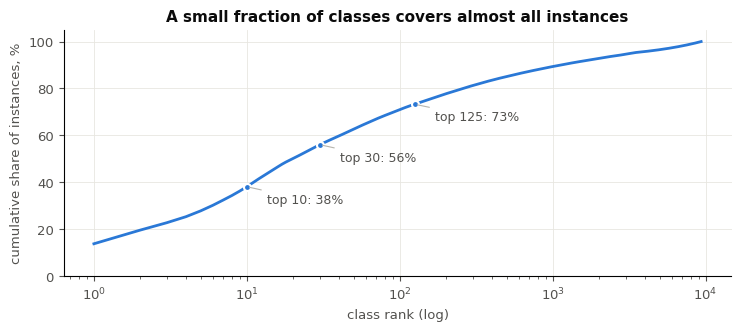

In [3]:
counts = ann_df.name.value_counts()

rows = []
for thr in [1, 2, 5, 10, 50, 100, 500]:
    kept = counts[counts >= thr]
    rows.append({"threshold (inst. ≥)": thr, "classes": len(kept),
                 "share of instances, %": round(kept.sum() / counts.sum() * 100, 1)})
display(pd.DataFrame(rows).set_index("threshold (inst. ≥)"))

cum = counts.cumsum() / counts.sum() * 100
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(range(1, len(cum) + 1), cum.values, color=C_STD, lw=2)
ax.set_xscale("log")
for k in (10, 30, 125):
    ax.annotate(f"top {k}: {cum.iloc[k-1]:.0f}%", xy=(k, cum.iloc[k - 1]),
                xytext=(k * 1.35, cum.iloc[k - 1] - 7), color=C_TEXT2, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=C_OTHER, lw=0.8))
    ax.plot([k], [cum.iloc[k - 1]], "o", color=C_STD, ms=5,
            mec="white", mew=1.5)
ax.set_xlabel("class rank (log)")
ax.set_ylabel("cumulative share of instances, %")
ax.set_title("A small fraction of classes covers almost all instances")
ax.set_ylim(0, 105)
plt.tight_layout(); plt.show()

**Section takeaway.** The ~9.4k-name vocabulary is an illusion: three quarters of
the names occur only 1–2 times. Everything that matters sits in the top hundred
classes, so the rest of the analysis focuses on it.

---
## 2. Most frequent classes: counts and mask sizes

For every class we compute the number of instances and scenes, plus the
**size profile** using COCO thresholds (small < 32², medium, large > 96² pixels).
The small share is critical: the model segments tiny masks poorly, and a class
dominated by small objects drags the mean mask AP down.

In [4]:
stats = (ann_df.groupby("name")
         .agg(instances=("name", "size"),
              images=("image_id", "nunique"),
              median_area=("area", "median"),
              pct_small=("area", lambda a: (a < AREA_SMALL).mean() * 100),
              pct_large=("area", lambda a: (a > AREA_LARGE).mean() * 100))
         .sort_values("instances", ascending=False))
stats["median_area"] = stats["median_area"].round(0)
stats[["pct_small", "pct_large"]] = stats[["pct_small", "pct_large"]].round(1)

stats.head(100).to_csv(ANALYSIS_DIR / "top_classes.csv")
display(stats.head(40))

,instances,images,median_area,pct_small,pct_large
name,,,,,
chair,17294,5729,6648.0,13.1,42.4
table,7262,4640,13476.0,7.6,58.4
window,4005,2678,10448.0,6.9,53.5
book,3210,1322,1484.0,38.7,8.1
picture,3140,1457,1948.0,32.1,13.7
door,2965,2359,10933.0,5.0,54.9
pillow,2775,1223,3364.0,14.8,16.8
desk,2471,1433,14153.0,8.1,58.7
cabinet,2374,1374,11276.0,5.4,55.3


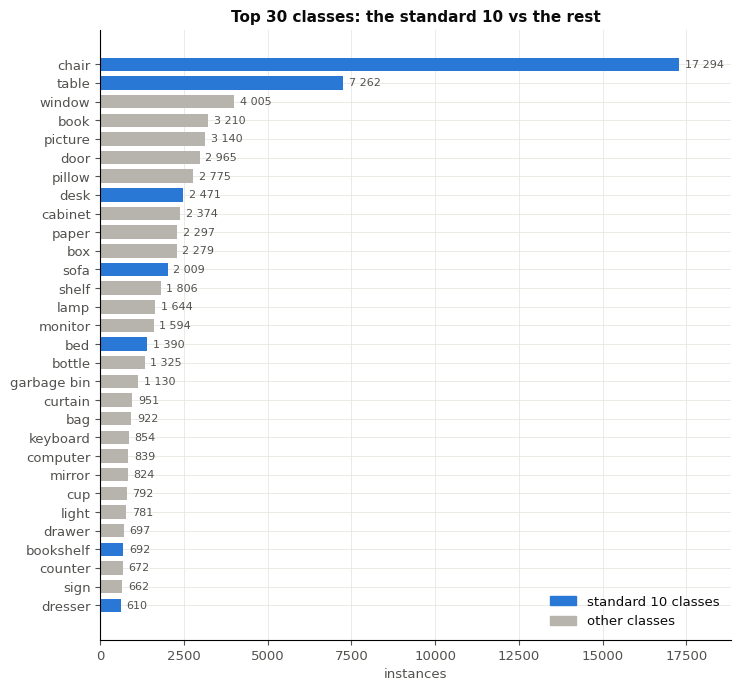

In [5]:
top30 = stats.head(30).iloc[::-1]
colors = [C_STD if n in sd.STANDARD_10_CLASSES else C_OTHER for n in top30.index]

fig, ax = plt.subplots(figsize=(7.5, 7))
bars = ax.barh(top30.index, top30.instances, color=colors, height=0.72)
for b, v in zip(bars, top30.instances):
    ax.text(v + top30.instances.max() * 0.01, b.get_y() + b.get_height() / 2,
            f"{v:,}".replace(",", " "), va="center", fontsize=8, color=C_TEXT2)
ax.set_xlabel("instances")
ax.set_title("Top 30 classes: the standard 10 vs the rest")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_STD, label="standard 10 classes"),
                   plt.Rectangle((0, 0), 1, 1, color=C_OTHER, label="other classes")],
          loc="lower right", frameon=False)
ax.margins(x=0.09)
plt.tight_layout(); plt.show()

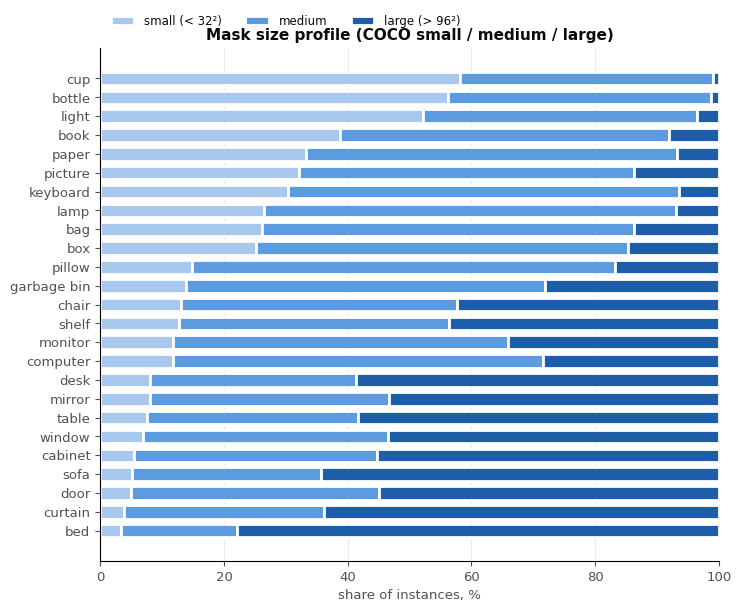

Bottom of the chart — classes with mostly large masks (easier for the model),
top — classes dominated by small masks (low expected AP).


In [6]:
top25 = stats.head(25).copy()
top25["pct_medium"] = 100 - top25.pct_small - top25.pct_large
top25 = top25.sort_values("pct_small")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
left = np.zeros(len(top25))
for frac, col, lab in [(top25.pct_small, SEQ_BLUE[0], "small (< 32²)"),
                       (top25.pct_medium, SEQ_BLUE[1], "medium"),
                       (top25.pct_large, SEQ_BLUE[2], "large (> 96²)")]:
    ax.barh(top25.index, frac, left=left, color=col, height=0.72,
            edgecolor="white", linewidth=2, label=lab)
    left += frac.values
ax.set_xlim(0, 100)
ax.set_xlabel("share of instances, %")
ax.set_title("Mask size profile (COCO small / medium / large)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3, frameon=False,
          fontsize=8.5)
plt.tight_layout(); plt.show()

print("Bottom of the chart — classes with mostly large masks (easier for the model),")
print("top — classes dominated by small masks (low expected AP).")

---
## 3. Hidden orthographic duplicates

`sunrgbd.normalize_name()` folds variants with spaces (`coffee table` → `table`),
but the dataset also contains many **concatenated spellings** (`coffeetable`,
`officechair`, `bedsidetable`) — currently they live as orphan classes and never
reach the target categories.

We find all classes whose name, after removing spaces/hyphens (and stripping the
plural "s"), matches an already accepted synonym. These are **purely orthographic**
losses: the semantics of these merges is already accepted in `SYNONYMS`; only the
spelling differs.

> **Status:** `normalize_name()` now handles concatenated spellings itself
> (the `_SQUASHED_SYNONYMS` fallback added on 2026-08-10), and the COCO files
> were regenerated. This section therefore acts as a **regression check** —
> the losses below should be (close to) zero.

In [7]:
def squash(s):
    return s.replace(" ", "").replace("-", "")

# all accepted aliases of each canonical name: the canon itself + SYNONYMS keys
aliases = defaultdict(set)
for k, v in sd.SYNONYMS.items():
    aliases[v].add(k.strip())
for canon in set(sd.SYNONYMS.values()) | set(sd.STANDARD_10_CLASSES):
    aliases[canon].add(canon)

sq2canon = {squash(a): c for c, al in aliases.items() for a in al}
# a few obvious typos that squashing alone does not catch
sq2canon.update({"chiar": "chair", "cabnet": "cabinet", "bathtube": "bathtub"})

def match_canon(name):
    sq = squash(name)
    canon = sq2canon.get(sq)
    if canon is None and sq.endswith("s"):        # plurals: chairs, sofas, ...
        canon = sq2canon.get(sq[:-1])
    return canon

lost = []
for name, n in counts.items():
    canon = match_canon(name)
    if canon and canon != name:
        lost.append({"canon": canon, "variant": name, "instances": n})
lost_df = pd.DataFrame(lost, columns=["canon", "variant", "instances"])

lost_df.sort_values("instances", ascending=False).to_csv(
    ANALYSIS_DIR / "orthographic_losses.csv", index=False)

if lost_df.empty:
    print("Regression check passed: no orthographic losses left — every")
    print("concatenated/plural variant is already folded by normalize_name().")
else:
    summary = (lost_df.groupby("canon")
               .agg(lost=("instances", "sum"),
                    variants=("variant", lambda v: ", ".join(
                        lost_df[lost_df["variant"].isin(v)]
                        .sort_values("instances", ascending=False)["variant"].head(6))))
               .sort_values("lost", ascending=False))
    summary["current"] = summary.index.map(lambda c: counts.get(c, 0))
    summary["gain, %"] = (summary["lost"] / summary["current"].replace(0, np.nan) * 100).round(1)
    summary = summary[["current", "lost", "gain, %", "variants"]]

    std_mask = summary.index.isin(sd.STANDARD_10_CLASSES)
    print(f"Losses of the standard 10 classes: {summary[std_mask]['lost'].sum()} instances")
    display(summary[std_mask])
    print("Other canonical names (useful if the class list is ever extended):")
    display(summary[~std_mask].head(15))

Regression check passed: no orthographic losses left — every
concatenated/plural variant is already folded by normalize_name().


---
## 4. Candidate groups for merging / adding

Potential merges fall into two kinds:

* **safe** — spelling variants of the same concept
  (`trashcan` = `garbage bin` = `recycle bin`; `cupboard` ≈ `cabinet`);
* **risky** — different concepts that are sometimes merged
  (`stool` → `chair`, `ottoman` → `sofa`, `mattress` → `bed`). Such merges add
  label noise, break comparability with the standard 10-class benchmark, and can
  produce duplicate masks in the same scene (a mattress on top of a bed).

For every candidate group we compute totals **per frozen split** — the main
viability criterion: is there enough training data, and is there anything to
evaluate on in val/test.

In [8]:
CANDIDATE_GROUPS = {
    "cabinet (+cupboard, file cabinet)": ["cabinet", "cupboard", "filecabinet",
                                          "filingcabinet", "cabnet", "kitchencabinet"],
    "pillow (+cushion)":       ["pillow", "throwpillow"],
    "lamp":                    ["lamp", "tablelamp", "desklamp", "floorlamp"],
    "display (monitor+tv)":    ["monitor", "computermonitor", "tvmonitor",
                                "television", "tvscreen"],
    "garbage bin (full group)": ["garbagebin", "trashcan", "dustbin", "garbagecan",
                                "recyclebin", "wastebin", "trashbin", "wastebasket"],
    "shelf":                   ["shelf", "shelving", "wallshelf"],
    "sink":                    ["sink", "washbasin", "bathroomsink", "kitchensink"],
    "fridge":                  ["fridge", "refrigerator", "refridgerator", "minifridge"],
    "whiteboard (+blackboard)":["whiteboard", "blackboard", "chalkboard"],
    "curtain":                 ["curtain"],
    "mirror":                  ["mirror"],
}

def group_members(squashed_list):
    sqs = set(squashed_list)
    return [n for n in counts.index
            if squash(n) in sqs or (squash(n).endswith("s") and squash(n)[:-1] in sqs)]

rows = []
for gname, sqs in CANDIDATE_GROUPS.items():
    members = group_members(sqs)
    sub = ann_df[ann_df.name.isin(members)]
    by_split = sub.groupby("split").size()
    val_imgs  = sub[sub.split == "val"].image_id.nunique()
    test_imgs = sub[sub.split == "test"].image_id.nunique()
    rows.append({"group": gname, "total": len(sub),
                 "train": by_split.get("train", 0), "val": by_split.get("val", 0),
                 "test": by_split.get("test", 0),
                 NO_SPLIT: by_split.get(NO_SPLIT, 0),
                 "val scenes": val_imgs, "test scenes": test_imgs})
cand_df = (pd.DataFrame(rows).set_index("group")
           .sort_values("total", ascending=False))
cand_df.to_csv(ANALYSIS_DIR / "candidate_groups_splits.csv")
display(cand_df)

# risky merges — volumes only, no recommendation to merge
RISKY = {"stool → chair": ["stool", "barstool"], "ottoman → sofa": ["ottoman"],
         "mattress, bed frame → bed": ["mattress", "bedframe"],
         "urinal → toilet": ["urinal"]}
risky_rows = [{"merge": k, "instances": int(counts[counts.index.isin(group_members(v))].sum())}
              for k, v in RISKY.items()]
print("Risky semantic merges (NOT recommended, for reference only):")
display(pd.DataFrame(risky_rows).set_index("merge"))

,total,train,val,test,no split,val scenes,test scenes
group,,,,,,,
"cabinet (+cupboard, file cabinet)",3095,1512,305,384,894,205,243
pillow (+cushion),2817,1976,387,387,67,181,182
display (monitor+tv),2011,1302,278,325,106,164,199
shelf,1847,1151,194,241,261,153,167
lamp,1666,1145,241,218,62,179,175
garbage bin (full group),1440,807,168,183,282,134,151
curtain,1029,658,155,142,74,126,113
mirror,824,459,110,103,152,97,82
whiteboard (+blackboard),770,532,114,96,28,96,82


Risky semantic merges (NOT recommended, for reference only):


,instances
merge,
stool → chair,407
ottoman → sofa,169
"mattress, bed frame → bed",246
urinal → toilet,59


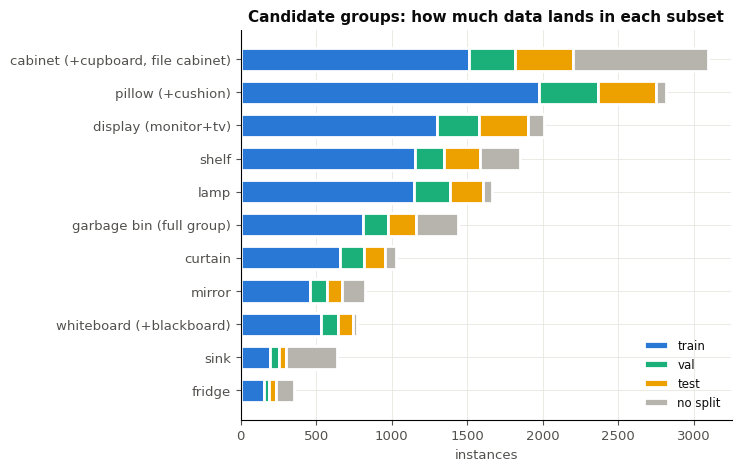

In [9]:
plot_df = cand_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
left = np.zeros(len(plot_df))
for col, colr in [("train", C_STD), ("val", C_ADD), ("test", C_ACCENT),
                  (NO_SPLIT, C_OTHER)]:
    ax.barh(plot_df.index, plot_df[col], left=left, color=colr, height=0.7,
            edgecolor="white", linewidth=2, label=col)
    left += plot_df[col].values
ax.set_xlabel("instances")
ax.set_title("Candidate groups: how much data lands in each subset")
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

---
## 5. Split coverage and "uncovered" scenes

The split in `split_assignment.csv` was built over scenes containing at least one
of the 10 standard classes. Scenes without any such object (mostly kitchens and
bathrooms) **received no split at all**. If the class list is extended, part of the
new classes' data will fall outside the subsets — let's estimate how much.

Scenes without a split: 1222 of 10294 (11.9%)


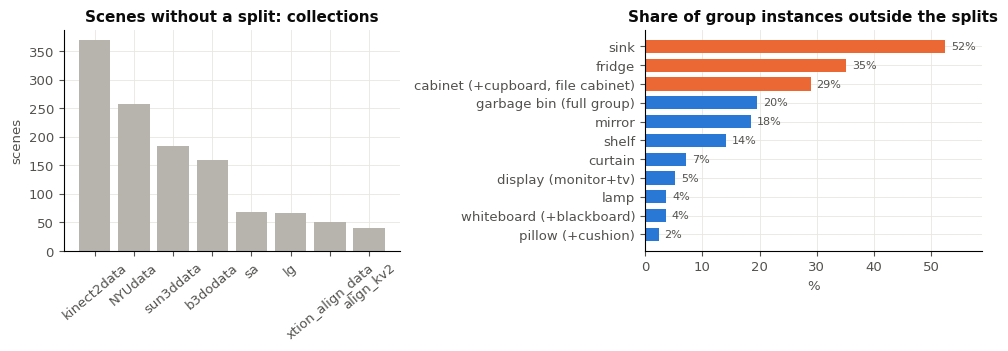

Orange groups (> 25% of data outside the splits) must not be added without
assigning the uncovered scenes to subsets first (new groups -> new CSV rows;
the existing 8,425 assignments are NOT touched).


In [10]:
img_split = {i: split_of_group.get(im["group_key"], NO_SPLIT)
             for i, im in img_by_id.items()}
no_split_imgs = [img_by_id[i] for i, s in img_split.items() if s == NO_SPLIT]
print(f"Scenes without a split: {len(no_split_imgs)} of {len(img_by_id)} "
      f"({len(no_split_imgs) / len(img_by_id) * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

coll = pd.Series([im["collection"] for im in no_split_imgs]).value_counts().head(8)
axes[0].bar(coll.index, coll.values, color=C_OTHER)
axes[0].set_title("Scenes without a split: collections")
axes[0].set_ylabel("scenes")
axes[0].tick_params(axis="x", rotation=40)

outside = (cand_df[NO_SPLIT] / cand_df["total"] * 100).sort_values()
bar_cols = [C_DROP if v > 25 else C_STD for v in outside.values]
axes[1].barh(outside.index, outside.values, color=bar_cols, height=0.7)
for y, v in enumerate(outside.values):
    axes[1].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8, color=C_TEXT2)
axes[1].set_title("Share of group instances outside the splits")
axes[1].set_xlabel("%")
axes[1].margins(x=0.12)
plt.tight_layout(); plt.show()

print("Orange groups (> 25% of data outside the splits) must not be added without")
print("assigning the uncovered scenes to subsets first (new groups -> new CSV rows;")
print("the existing 8,425 assignments are NOT touched).")

---
## 6. Exclusion candidates

Three reasons not to use a class for instance segmentation with a subsequent
transition to 3D:

* **planar / "stuff"-like** — parts of the room or nearly flat objects:
  instance boundaries are ill-defined, and for point clouds and spatial object
  properties (chapter 3) they carry no meaning;
* **tiny** — most masks are < 32² pixels: at ~640 px input the model barely
  segments such objects, and the class only drags the mean mask AP down;
* **amorphous** — fuzzy boundaries and inconsistent annotation (a pile of
  clothes, a stack of paper).

In [11]:
EXCLUDE = {
    "planar / stuff": ["window", "door", "curtain", "blinds", "mirror",
                       "whiteboard", "picture", "poster", "painting", "carpet",
                       "rug", "counter", "baseboard", "pillar", "board", "sign"],
    "tiny":           ["mouse", "outlet", "cup", "bottle", "faucet", "plate",
                       "bowl", "glass", "vase", "tag", "pricetag", "speaker"],
    "amorphous":      ["clothes", "cloth", "towel", "paper", "box", "bag",
                       "book", "blanket", "pipe"],
}
rows = []
for reason, names in EXCLUDE.items():
    for n in names:
        if n in stats.index:
            s = stats.loc[n]
            rows.append({"class": n, "reason": reason,
                         "instances": int(s.instances),
                         "median area": int(s.median_area),
                         "% small": s.pct_small, "% large": s.pct_large})
excl_df = (pd.DataFrame(rows).set_index("class")
           .sort_values(["reason", "instances"], ascending=[True, False]))
excl_df.to_csv(ANALYSIS_DIR / "exclusion_candidates.csv")
display(excl_df)

n_excl = excl_df["instances"].sum()
print(f"Together these classes cover {n_excl} instances "
      f"({n_excl / len(ann_df) * 100:.1f}% of the dataset) — big numbers do not mean")
print("a class is usable: window/door instance boundaries are arbitrary, and 82% of mouse masks are < 32².")

,reason,instances,median area,% small,% large
class,,,,,
book,amorphous,3210,1484,38.7,8.1
paper,amorphous,2297,1628,33.2,6.8
box,amorphous,2279,2393,25.1,14.7
bag,amorphous,922,2626,26.2,13.8
clothes,amorphous,519,3374,16.6,22.4
towel,amorphous,509,4384,13.2,25.7
blanket,amorphous,320,10226,5.0,52.5
cloth,amorphous,276,3593,15.6,23.6
pipe,amorphous,255,1783,32.2,9.4


Together these classes cover 32302 instances (25.8% of the dataset) — big numbers do not mean
a class is usable: window/door instance boundaries are arbitrary, and 82% of mouse masks are < 32².


---
## 7. Final class map

Every class in the top 100 is a point: frequency vs typical mask size. Color =
role in the proposed scheme. A "good" class for this task sits in the upper right:
many instances and large masks.

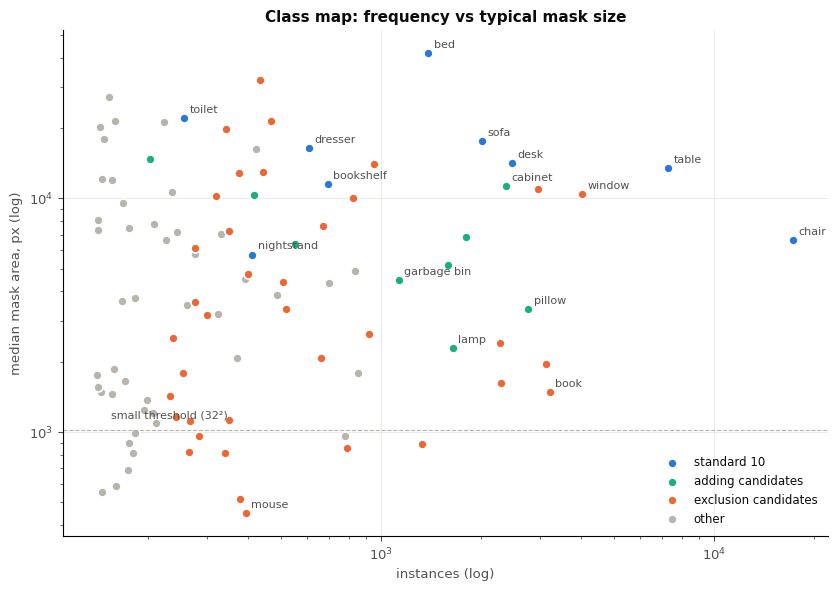

In [12]:
ADD_SET = {"cabinet", "pillow", "lamp", "monitor", "television", "garbage bin",
           "shelf", "sink", "fridge"}
EXCL_SET = {n for names in EXCLUDE.values() for n in names}

top100 = stats.head(100)
roles, role_colors = [], {"standard 10": C_STD, "adding candidates": C_ADD,
                          "exclusion candidates": C_DROP, "other": C_OTHER}
for n in top100.index:
    if n in sd.STANDARD_10_CLASSES: roles.append("standard 10")
    elif n in ADD_SET:              roles.append("adding candidates")
    elif n in EXCL_SET:             roles.append("exclusion candidates")
    else:                           roles.append("other")

fig, ax = plt.subplots(figsize=(8.5, 6))
for role in role_colors:
    idx = [i for i, r in enumerate(roles) if r == role]
    sub = top100.iloc[idx]
    z = 3 if role != "other" else 2
    ax.scatter(sub.instances, sub.median_area, s=42, color=role_colors[role],
               label=role, edgecolors="white", linewidths=1.2, zorder=z)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(AREA_SMALL, color=C_OTHER, lw=0.8, ls="--")
ax.text(top100.instances.min() * 1.1, AREA_SMALL * 1.12, "small threshold (32²)",
        fontsize=8, color=C_TEXT2)
for n in list(sd.STANDARD_10_CLASSES) + ["cabinet", "garbage bin", "window",
                                          "mouse", "book", "pillow", "lamp"]:
    if n in top100.index:
        s = top100.loc[n]
        ax.annotate(n, (s.instances, s.median_area), xytext=(4, 4),
                    textcoords="offset points", fontsize=8, color=C_TEXT2)
ax.set_xlabel("instances (log)")
ax.set_ylabel("median mask area, px (log)")
ax.set_title("Class map: frequency vs typical mask size")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

---
## Conclusions

The numbers below reflect the current artifacts in `outputs/` (see the
computations above).

**1. The vocabulary is inflated, but the core is stable.** Of ~9.4k names only
~125 have ≥ 100 instances; the top 30 classes cover ~55% of all objects. The
standard 10 classes are all in the top 70 by frequency, with mostly large masks.

**2. [FIXED 2026-08-10] Concatenated spellings recovered ~600 core instances.**
`coffeetable`, `officechair`, `bedsidetable`, `chestofdrawers` etc. used to live
as orphan classes. `normalize_name()` now folds such spellings (and their
plurals) into the accepted synonyms, the COCO files and splits were regenerated:
the standard 10 gained +601 instances (nightstand +18%, dresser +4.5%,
table +261), and the non-standard `garbage bin` group grew 435 → 1,130. All
8,425 existing scene-to-subset assignments were preserved; 36 newly qualifying
scenes were appended (24 train / 6 val / 6 test), no leak.

**3. Viable adding candidates** (if an extended list is needed, e.g. for the 3D
part of the thesis): `pillow`, `lamp`, `display` (monitor+tv), `garbage bin`
(a group of ~1,430 instances instead of 435 under a single spelling). Be careful
with:

* `cabinet` — large (≈3,000 instances incl. cupboard) but visually confusable
  with `dresser` from the standard ten;
* `sink`, `fridge`, `counter` — 25–50% of their data sits in scenes **outside
  the splits** (kitchens/bathrooms with no standard classes); add them only
  after assigning the 1,254 uncovered scenes (without touching existing
  assignments).

**4. Do not use:** planar/stuff (window, door, curtain, mirror, whiteboard,
picture...), tiny (mouse, outlet, cup, bottle — 45–85% of masks below 32²), and
amorphous (clothes, paper, box, bag) classes. Their large counts are deceptive:
annotation quality and geometry make them harmful for mean AP and useless for
point clouds.

**5. Avoid risky merges:** stool→chair, ottoman→sofa, mattress→bed,
urinal→toilet — different concepts; merging adds label noise, breaks
comparability with the standard benchmark (and a mattress also duplicates masks
on top of the bed).